In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from lib_pca.utils_sqrtm import sqrtm
from lib_pca.utils_plot import draw_cov
from lib_pca.lifted_pca import LiftedPCA
from lib_pca.uncertainty_aware_pca import UAPCA

[KeOps] Warning : CUDA libraries not found or could not be loaded; Switching to CPU only.


In [2]:
from sklearn import datasets
iris = datasets.load_iris()

In [3]:
X = iris.data

In [4]:
X.shape

(150, 4)

In [5]:
## PCA
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X)

In [6]:
X_reduced.shape

(150, 2)

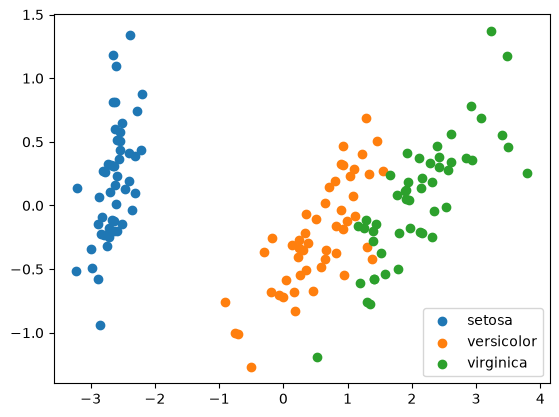

In [7]:
for k in range(3):
    plt.scatter(X_reduced[iris.target==k, 0], X_reduced[iris.target==k, 1], label=iris.target_names[k])

plt.legend()
plt.show()

In [8]:
for k in range(3):
    print((X[iris.target==k].shape))

(50, 4)
(50, 4)
(50, 4)


In [ ]:
# Fix the support and optim over weights only
samples_iris = [torch.from_numpy(X[iris.target==k]) for k in range(3)]

lifted_pca = LiftedPCA(n_components=2, n_samples=100)
lifted_pca.fit(samples_iris, solver="fixed_support", seed=42, n_iter_bary=500, stop_threshold_fixed_support=1e-20, lr_bary=0.1)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA(2)
pca_distributional.fit_from_samples(torch.from_numpy(X), torch.from_numpy(iris.target))
eigenvectors_distributional = pca_distributional.components_# .numpy()

print("Barycenter cost:", lifted_pca.cost_barycenter(samples_iris))

INFO:2026-08-25 14:31:37,704:jax._src.xla_bridge:812: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
INFO: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory


Barycenter cost: 0.1940181577530422


In [10]:
lifted_pca.weights_

tensor([3.7525e-07, 3.0240e-06, 7.0202e-06, 6.7128e-06, 4.9918e-06, 4.1819e-07,
        1.1951e-06, 9.0038e-07, 1.4096e-06, 3.4872e-07, 9.9759e-06, 4.9503e-06,
        2.3444e-06, 4.1228e-07, 4.6819e-07, 1.1125e-06, 4.5692e-07, 5.4573e-07,
        1.7358e-06, 7.4126e-07, 1.9883e-04, 6.7147e-07, 7.1937e-07, 1.1586e-06,
        4.5393e-06, 8.1775e-07, 1.3316e-06, 7.9436e-06, 1.9144e-06, 2.7880e-05,
        3.9286e-06, 3.9536e-06, 3.9976e-07, 4.6643e-04, 4.0838e-06, 1.0927e-06,
        1.5164e-06, 9.8932e-06, 5.2029e-06, 2.3279e-06, 8.2864e-06, 7.0030e-06,
        1.7258e-06, 2.3093e-05, 3.4893e-07, 6.3675e-06, 2.3867e-05, 1.7740e-06,
        1.5232e-06, 7.7036e-07, 4.2511e-07, 6.1296e-07, 4.4066e-07, 2.0825e-06,
        7.6423e-07, 7.2363e-07, 6.0683e-07, 7.8326e-07, 2.1119e-06, 3.1105e-05,
        3.2288e-05, 7.5184e-07, 6.4127e-07, 7.6955e-05, 5.7595e-07, 8.7170e-04,
        1.8765e-06, 4.1012e-07, 2.1929e-05, 6.1024e-07, 3.3680e-07, 3.9176e-07,
        3.2279e-07, 8.6069e-07, 4.2633e-

In [11]:
lifted_pca.components_[np.argmax(lifted_pca.weights_)]

tensor([[-0.7458,  0.0570],
        [-0.4878, -0.2441],
        [ 0.0688,  0.9166],
        [-0.4484,  0.3115]])

In [12]:
pca_distributional.components_.T

tensor([[-0.3614,  0.6566],
        [ 0.0845,  0.7302],
        [-0.8567, -0.1734],
        [-0.3583, -0.0755]])

In [13]:
lifted_pca.components_.shape

torch.Size([100, 4, 2])

In [16]:
X.shape

(150, 4)

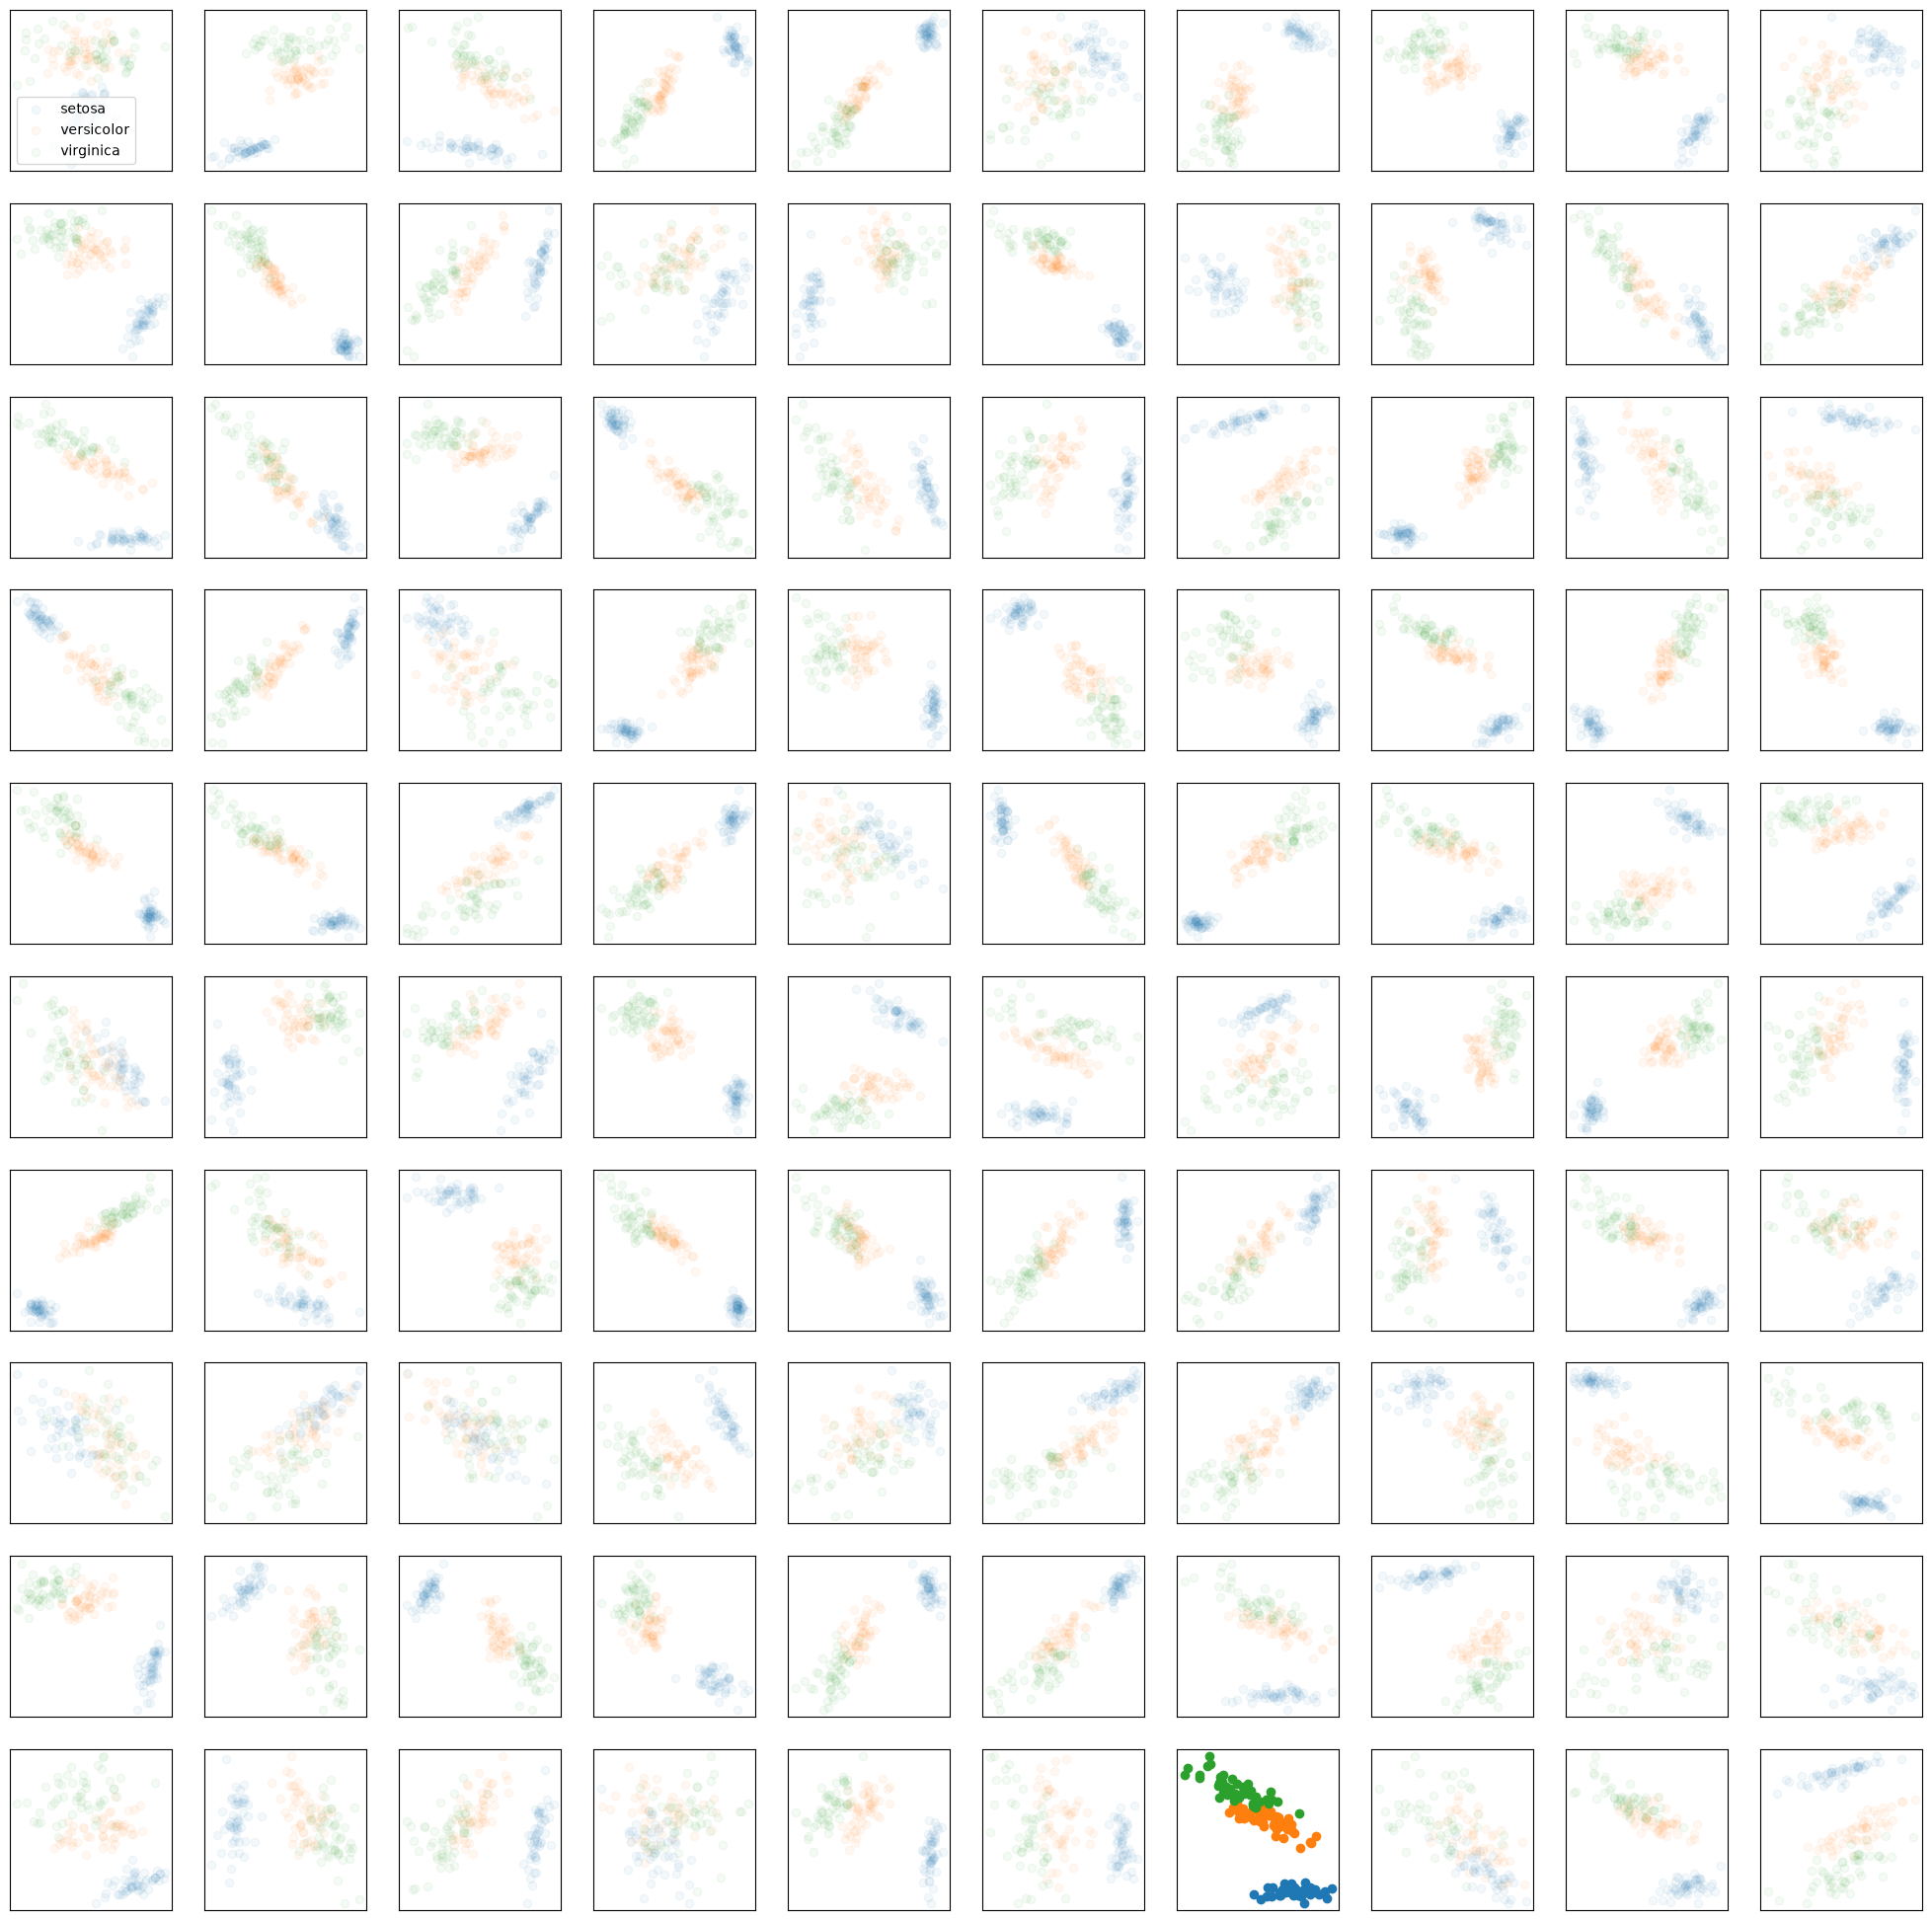

In [24]:
weights = lifted_pca.weights_.numpy()
min_weights = weights.min()
max_weights = weights.max()
diff = max_weights - min_weights
alpha = 0.05 + 0.95 * (weights - min_weights) / diff

fig, axes = plt.subplots(
    nrows=10, 
    ncols=10,
    figsize=(25,25)
)

for i in range(10):
    for j in range(10):
        U = lifted_pca.components_[i*10+j]
        proj_points = torch.einsum("ij, ki -> kj", U, torch.from_numpy(X)).numpy()
        for k in range(3):
            axes[i, j].scatter(proj_points[iris.target == k, 0], proj_points[iris.target == k, 1], label=iris.target_names[k], alpha=alpha[i*10+j])

        if i == 0 and j == 0:
            axes[i, j].legend()

        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])

plt.show()

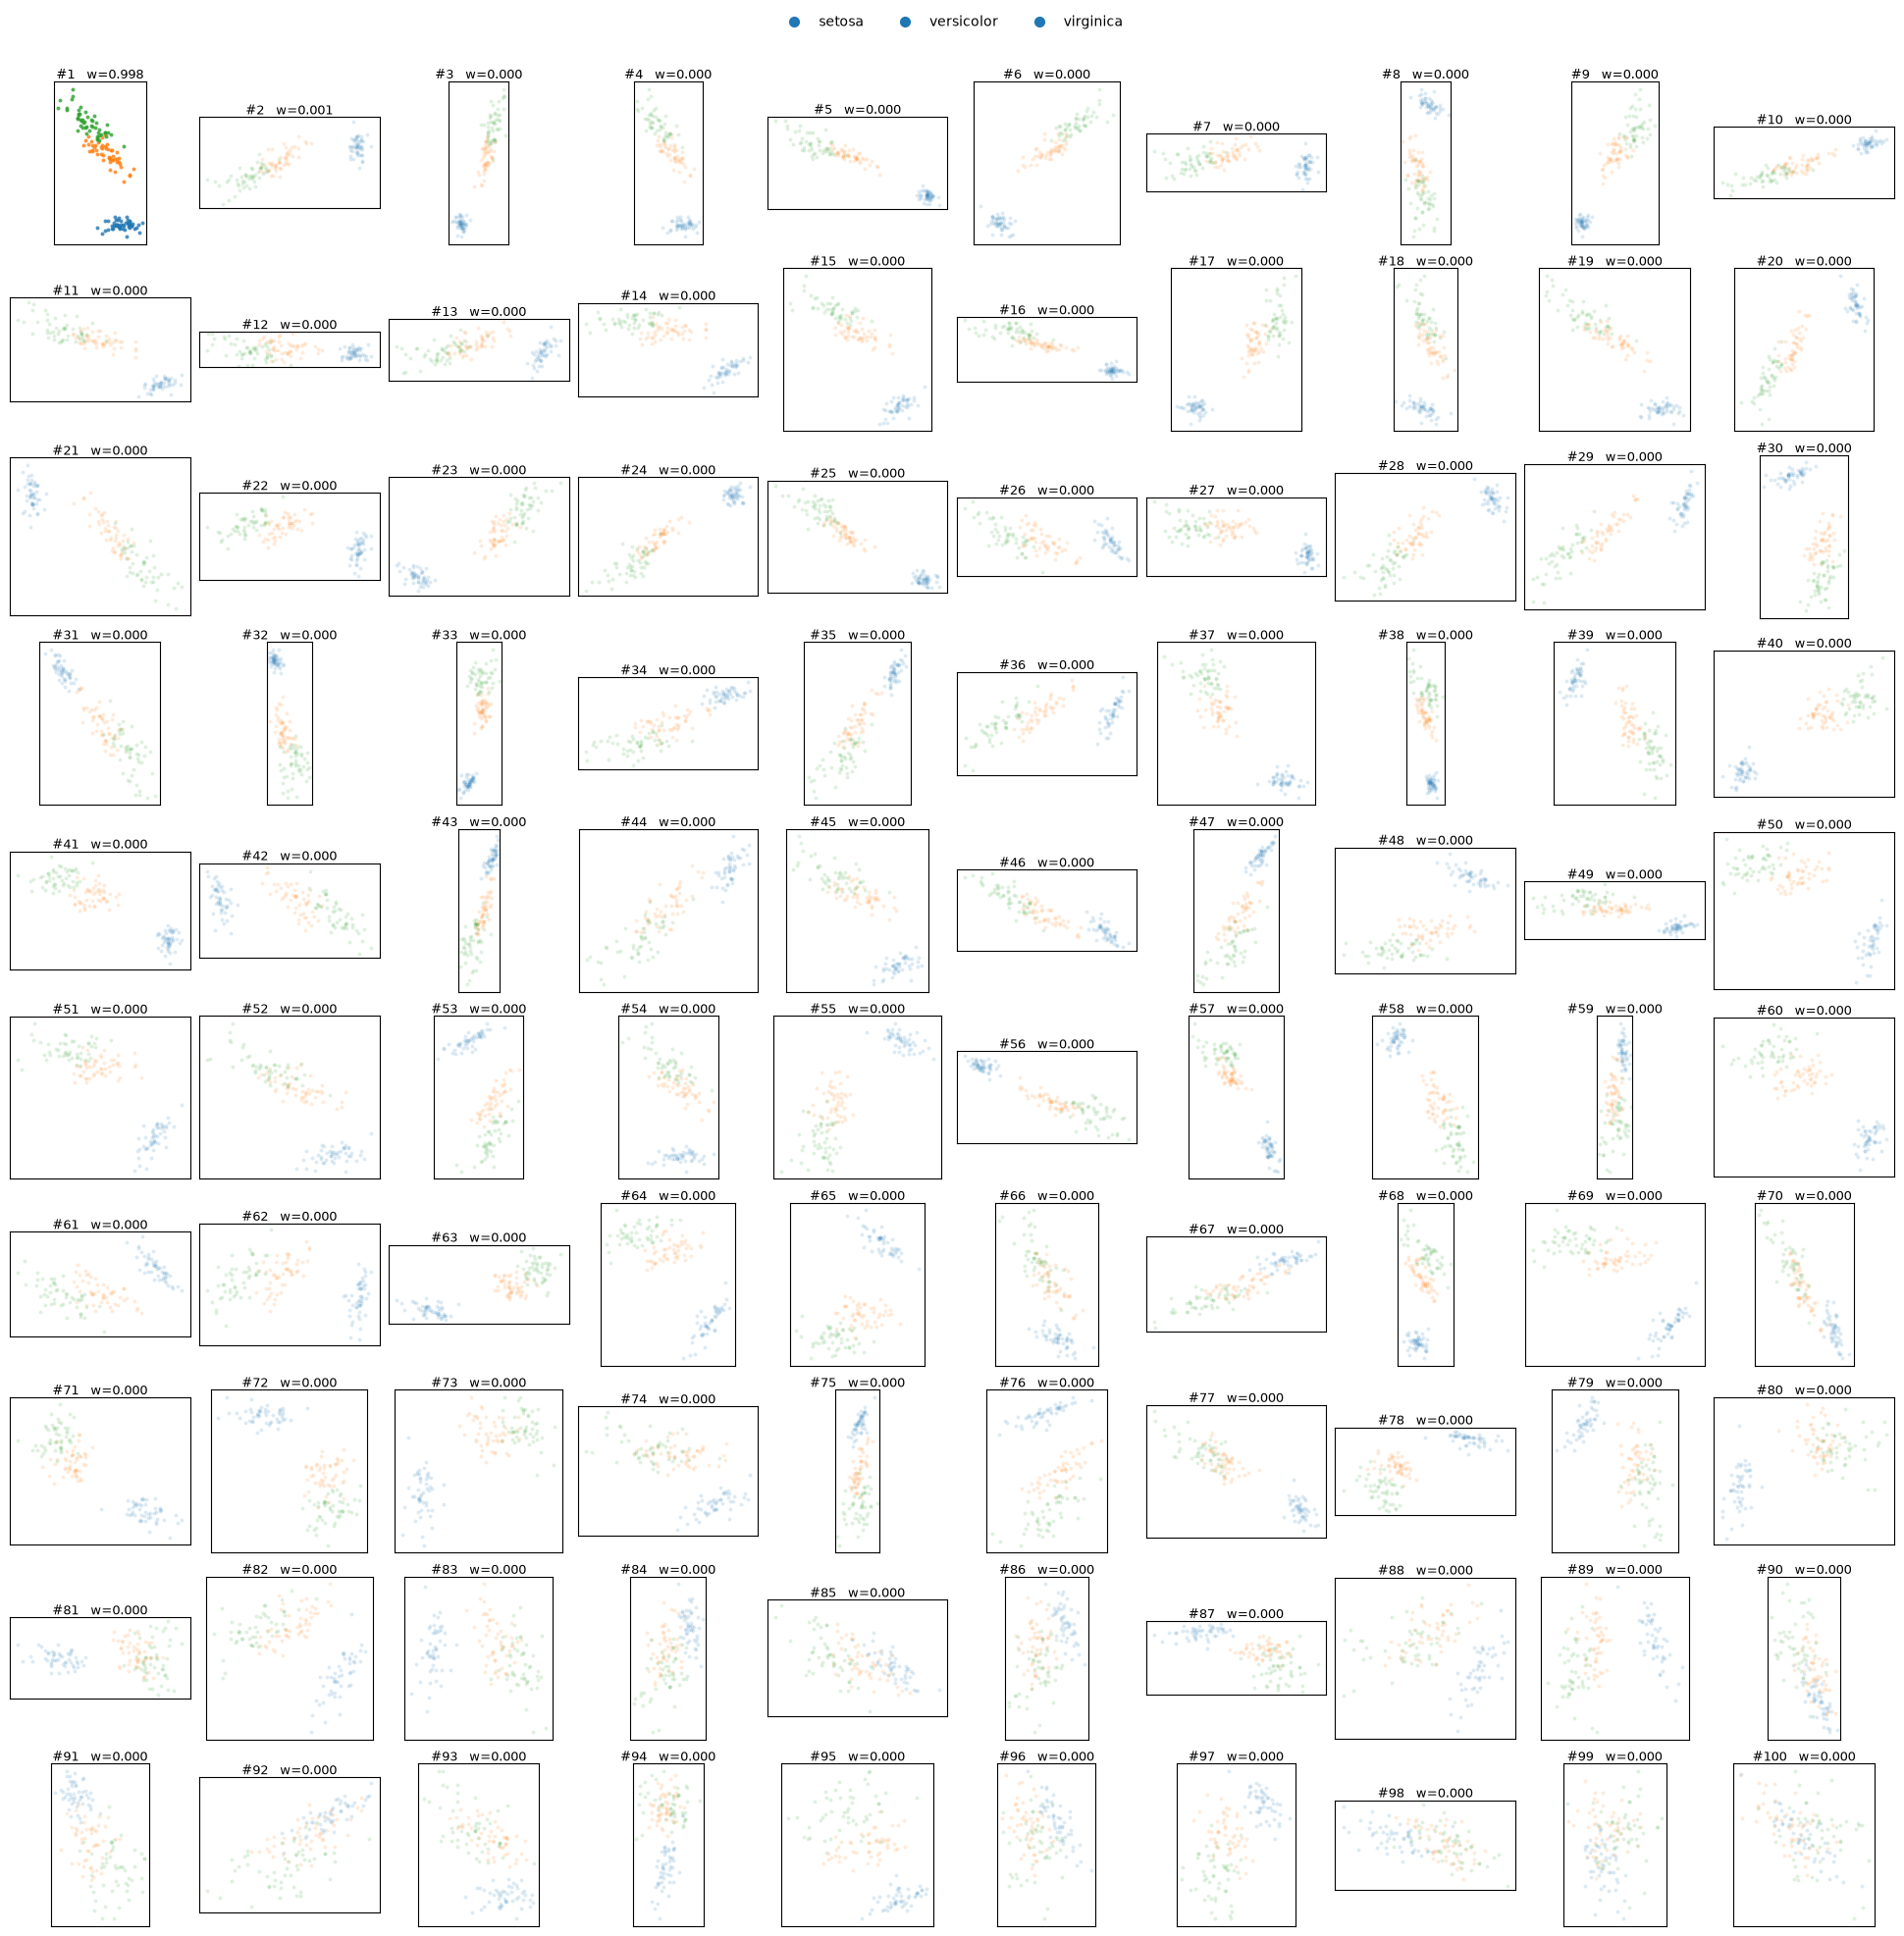

In [26]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# Data
# ------------------------------------------------------------
weights = lifted_pca.weights_.detach().cpu().numpy()

# Sort planes by decreasing weight
order = np.argsort(weights)[::-1]

weights_sorted = weights[order]

# Robust normalization of weights
w = (weights_sorted - weights_sorted.min()) / (
    weights_sorted.max() - weights_sorted.min() + 1e-12
)

# Alpha for points: don't make low-weight planes completely disappear
point_alpha = 0.15 + 0.65 * w


# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------
fig, axes = plt.subplots(
    nrows=10,
    ncols=10,
    figsize=(20, 20),
)

X_torch = torch.from_numpy(X)

for plot_idx, plane_idx in enumerate(order):

    i, j = divmod(plot_idx, 10)

    ax = axes[i, j]

    # --------------------------------------------------------
    # Project data onto this 2D plane
    # U: (4, 2)
    # X: (N, 4)
    # --------------------------------------------------------
    U = lifted_pca.components_[plane_idx]

    if isinstance(U, torch.Tensor):
        U = U.detach().cpu()

    proj_points = X_torch @ U
    proj_points = proj_points.numpy()

    # --------------------------------------------------------
    # Plot the three classes
    # --------------------------------------------------------
    for k in range(3):
        mask = iris.target == k

        ax.scatter(
            proj_points[mask, 0],
            proj_points[mask, 1],
            s=8,
            alpha=point_alpha[plot_idx],
            linewidths=0,
            label=iris.target_names[k],
        )

    # --------------------------------------------------------
    # Plane information
    # --------------------------------------------------------
    ax.set_title(
        f"#{plot_idx + 1}   w={weights[plane_idx]:.3f}",
        fontsize=9,
        pad=2,
    )

    ax.set_xticks([])
    ax.set_yticks([])

    # Equal aspect ratio is important:
    # otherwise the geometry of the projected plane is distorted.
    ax.set_aspect("equal", adjustable="box")


# ------------------------------------------------------------
# One global legend
# ------------------------------------------------------------
handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markersize=7,
        label=iris.target_names[k],
    )
    for k in range(3)
]

fig.legend(
    handles=handles,
    loc="upper center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 1.0),
)

fig.subplots_adjust(
    left=0.02,
    right=0.98,
    bottom=0.02,
    top=0.96,
    wspace=0.05,
    hspace=0.15,
)

plt.show()

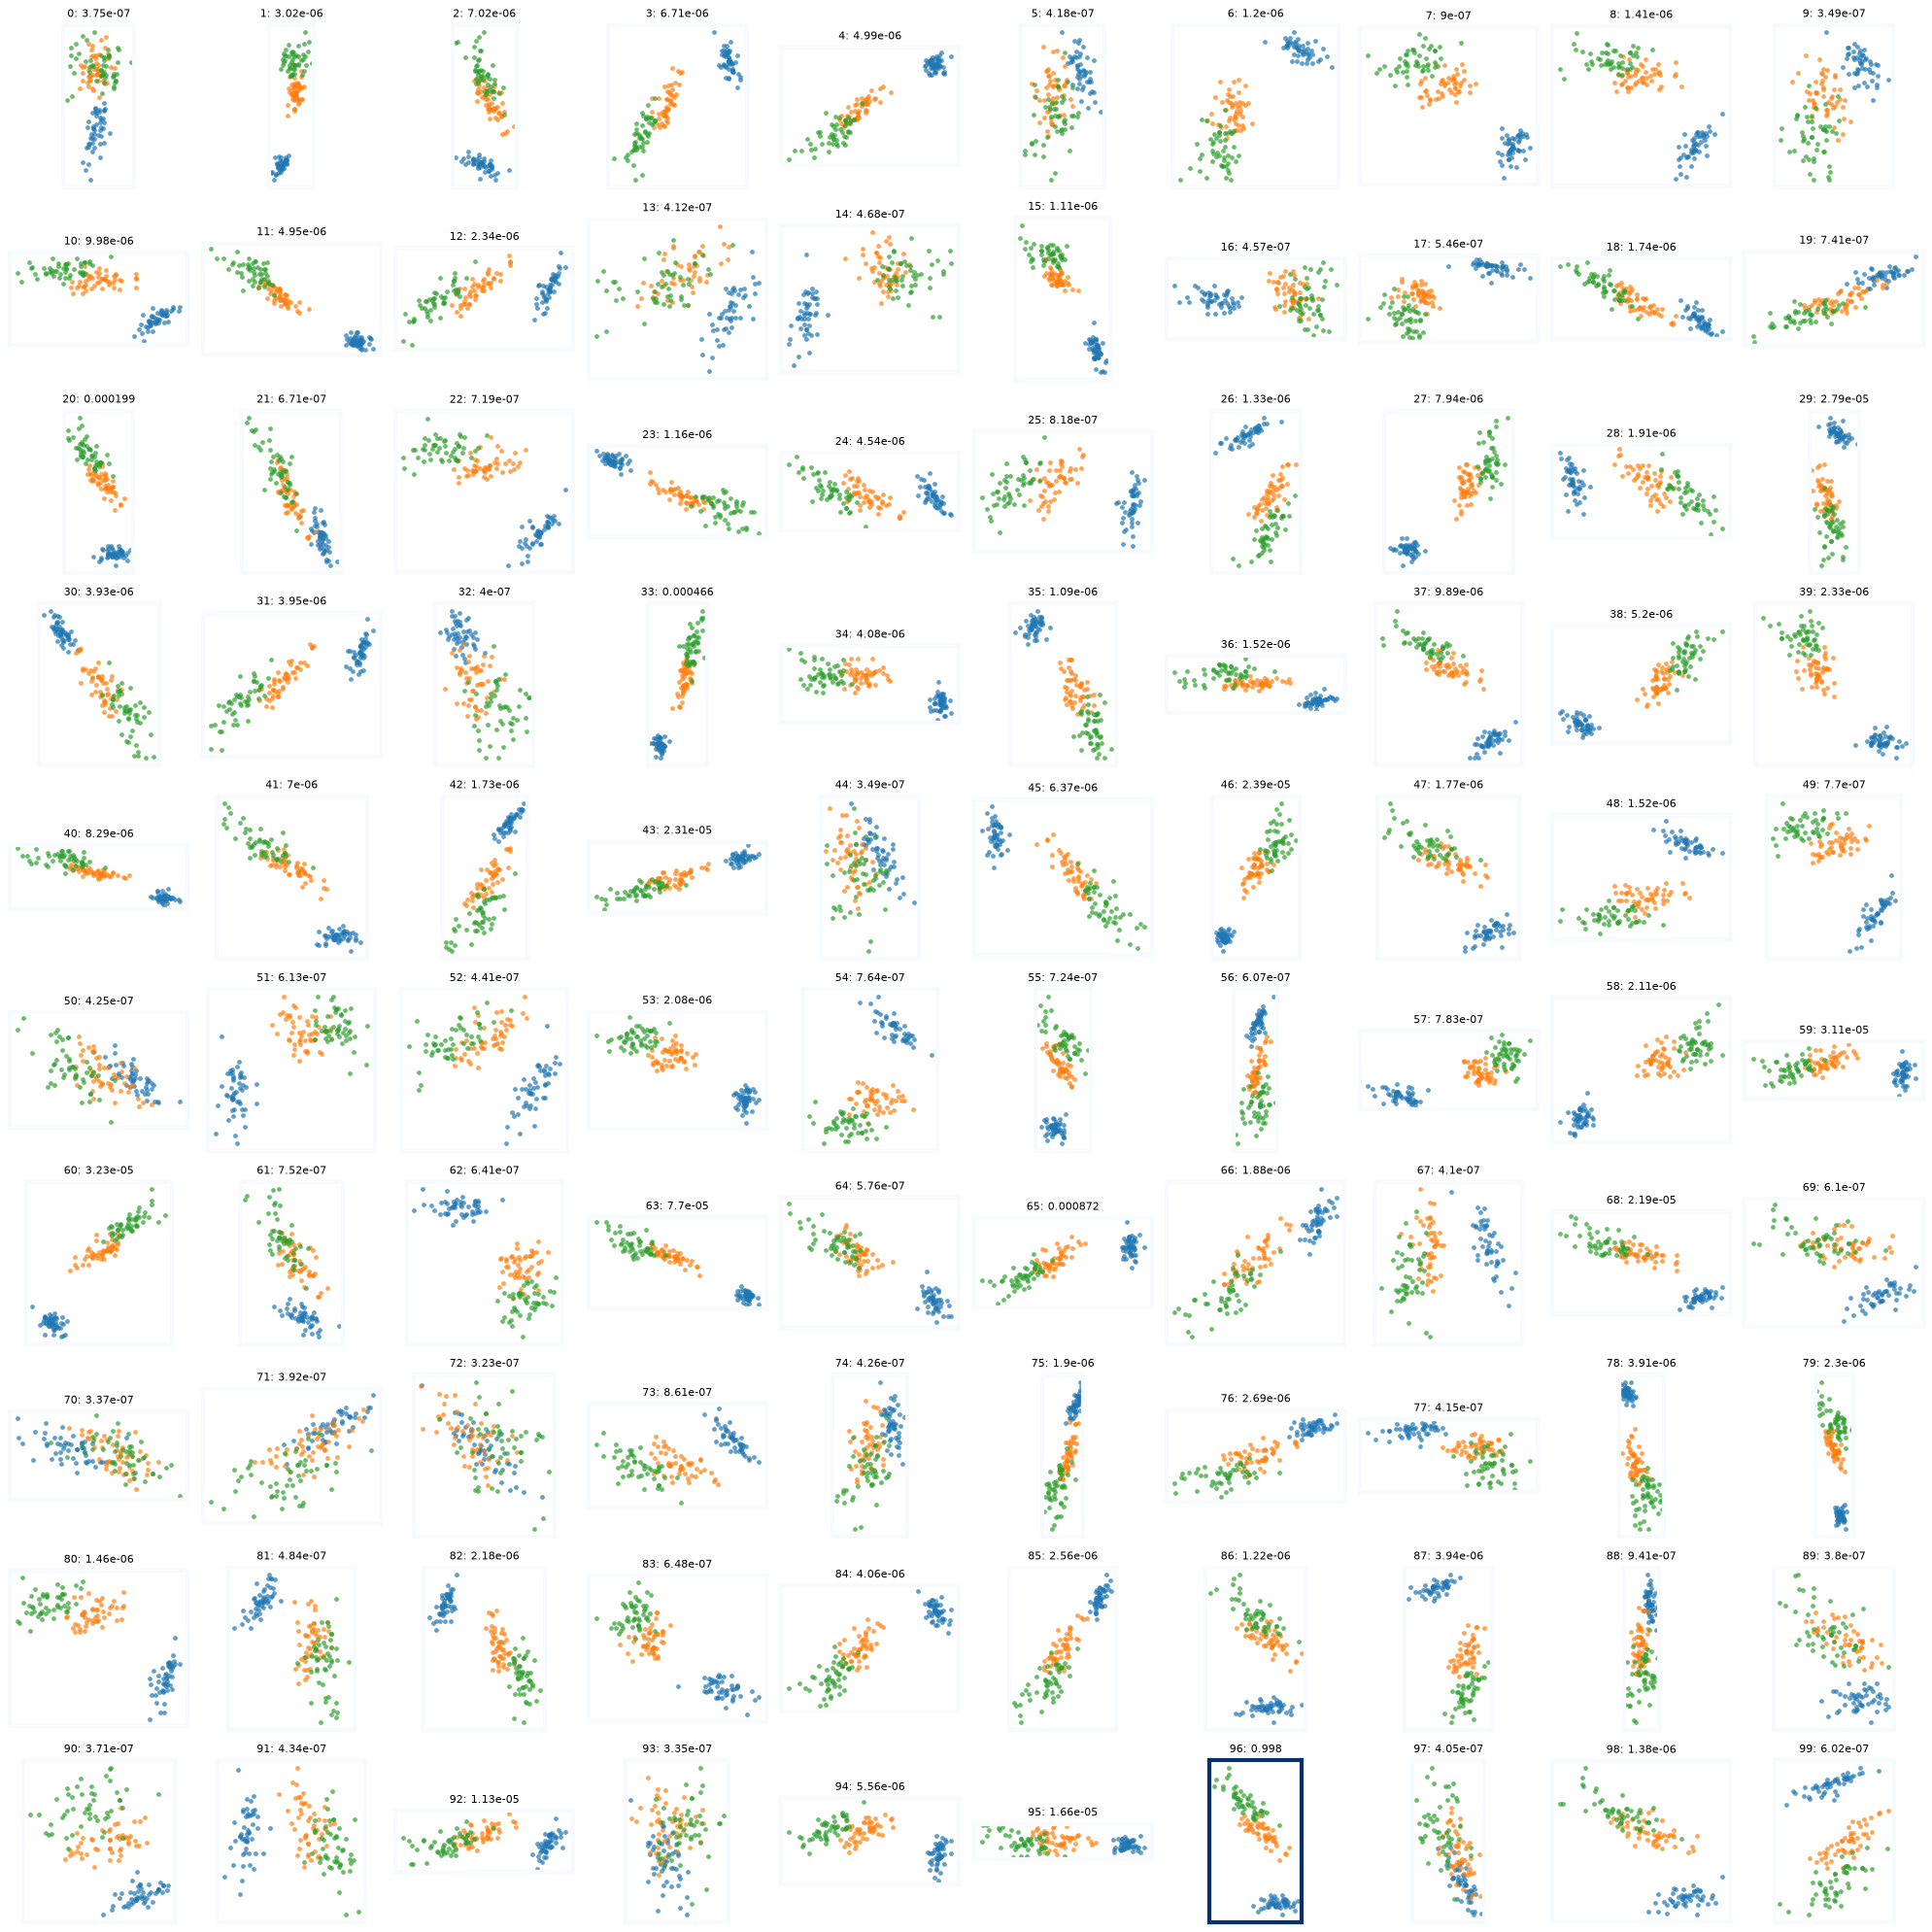

In [33]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib import colormaps

weights = lifted_pca.weights_.detach().cpu().numpy()

# Normalize weights
w = (weights - weights.min()) / (
    weights.max() - weights.min() + 1e-12
)

cmap = colormaps["Blues"]

fig, axes = plt.subplots(
    10, 10,
    figsize=(20, 20),
)

for idx, ax in enumerate(axes.flat):

    # Your original plane
    U = lifted_pca.components_[idx]

    # Your original projection -- DO NOT CHANGE THIS
    proj_points = torch.einsum(
        "ij,ki->kj",
        U,
        torch.from_numpy(X)
    ).numpy()

    # Plot classes
    for k in range(3):
        mask = iris.target == k

        ax.scatter(
            proj_points[mask, 0],
            proj_points[mask, 1],
            s=12,
            alpha=0.7,
            linewidths=0,
        )

    # Weight represented by the border
    color = cmap(w[idx])

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(3)
        spine.set_color(color)

    ax.set_title(
        f"{idx}: {weights[idx]:.3g}",
        fontsize=8,
    )

    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [31]:
# Z = pca_distributional.components_
Z = lifted_pca.components_[np.argmax(lifted_pca.weights_)]

In [33]:
Z.T @ Z

tensor([[1.0000, 0.0000],
        [0.0000, 1.0000]], dtype=torch.float64)

In [36]:
lifted_pca.components_[np.argmax(lifted_pca.weights_)].shape

torch.Size([4, 2])